In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '2'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from utils.models import *
from utils.dataloader import *
from utils.utils_sig import *


추론 완료: preds (373, 300), targets (373, 300)


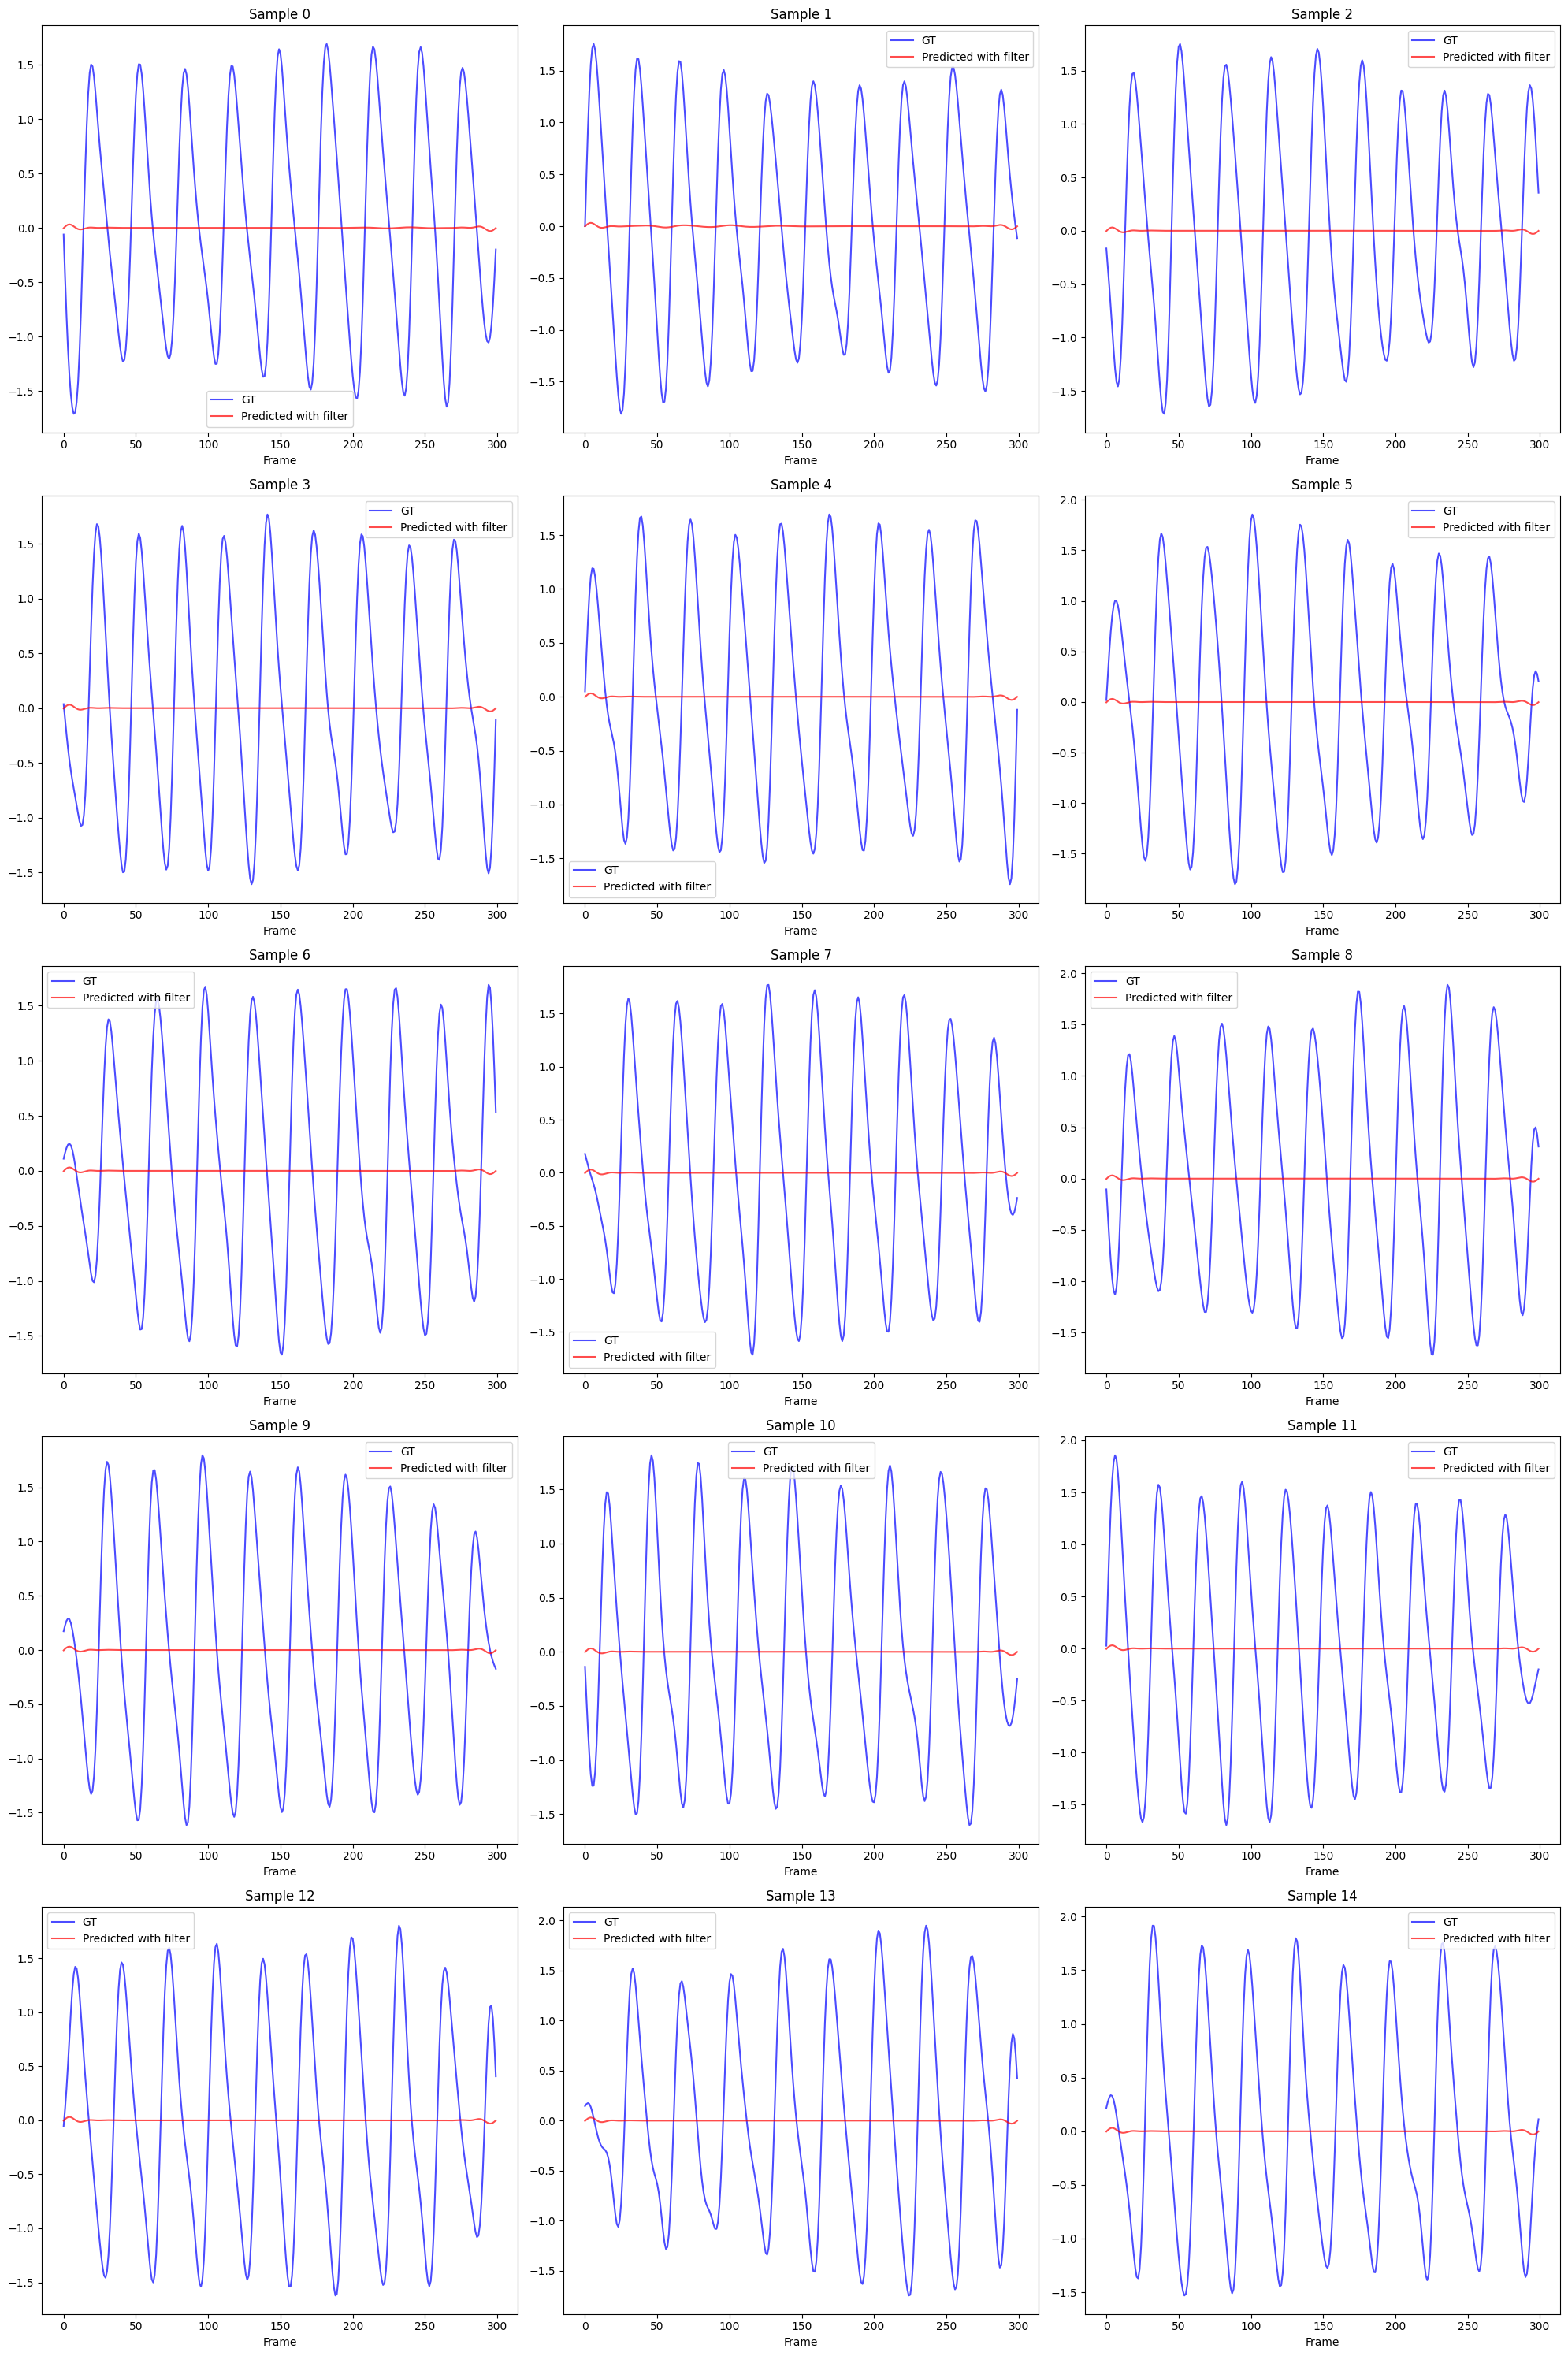

In [11]:
# # ===== 설정 =====
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# pth_path = '/home/son/orientation-uv-rppg/data/codes/deeplearning/physent_data_wo_ol_lr:0.0005_epoch:1_MAE:6.683274021352313.pth'
# data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300'
# pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'
# # ===== 모델 로드 =====
# model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
# model.load_state_dict(torch.load(pth_path, map_location=device))
# model.eval()
# print("모델 로드 완료")

# # ===== 데이터 로드 =====
# all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
# valid_files = all_files[13:14]
# valid_dataset = rPPGDataset(valid_files)
# valid_loader  = DataLoader(valid_dataset, batch_size=24, shuffle=False, num_workers=4)

# # ===== 추론 =====
# all_preds   = []
# all_targets = []
# all_preds_with_filter = []

# with torch.no_grad():
#     for inputs, targets in valid_loader:
#         inputs  = inputs.to(device)
#         outputs, _, _, _ = model(inputs)

#         all_preds.append(outputs.cpu().numpy())
#         all_targets.append(targets.numpy())

# all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
# all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

# for i in range(len(all_preds)) :
#     all_preds_with_filter.append(butter_bandpass_filter(all_preds[i], 0.66, 2.5, 30))

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

# ===== Plot =====
n_plot = 15  # 몇 개 샘플 볼지
fig, axes = plt.subplots(5, 3, figsize=(20, 30))
axes = axes.flatten()

for i in range(n_plot):
    axes[i].plot(all_targets[i], label='GT',        color='blue',  alpha=0.7)
    axes[i].plot(all_preds_with_filter[i],   label='Predicted with filter', color='red',   alpha=0.7)
#    axes[i].plot(15*all_preds[i],   label='Predicted', color='green',   alpha=0.7)
#    axes[i].set_ylim(-1.5,1.5)
    axes[i].set_title(f'Sample {i}')
    axes[i].legend()
    axes[i].set_xlabel('Frame')

plt.tight_layout()
plt.savefig(os.path.join(pic_save_dir, 'nirp_uv_valid_timedomain'), dpi= 100)
plt.show()



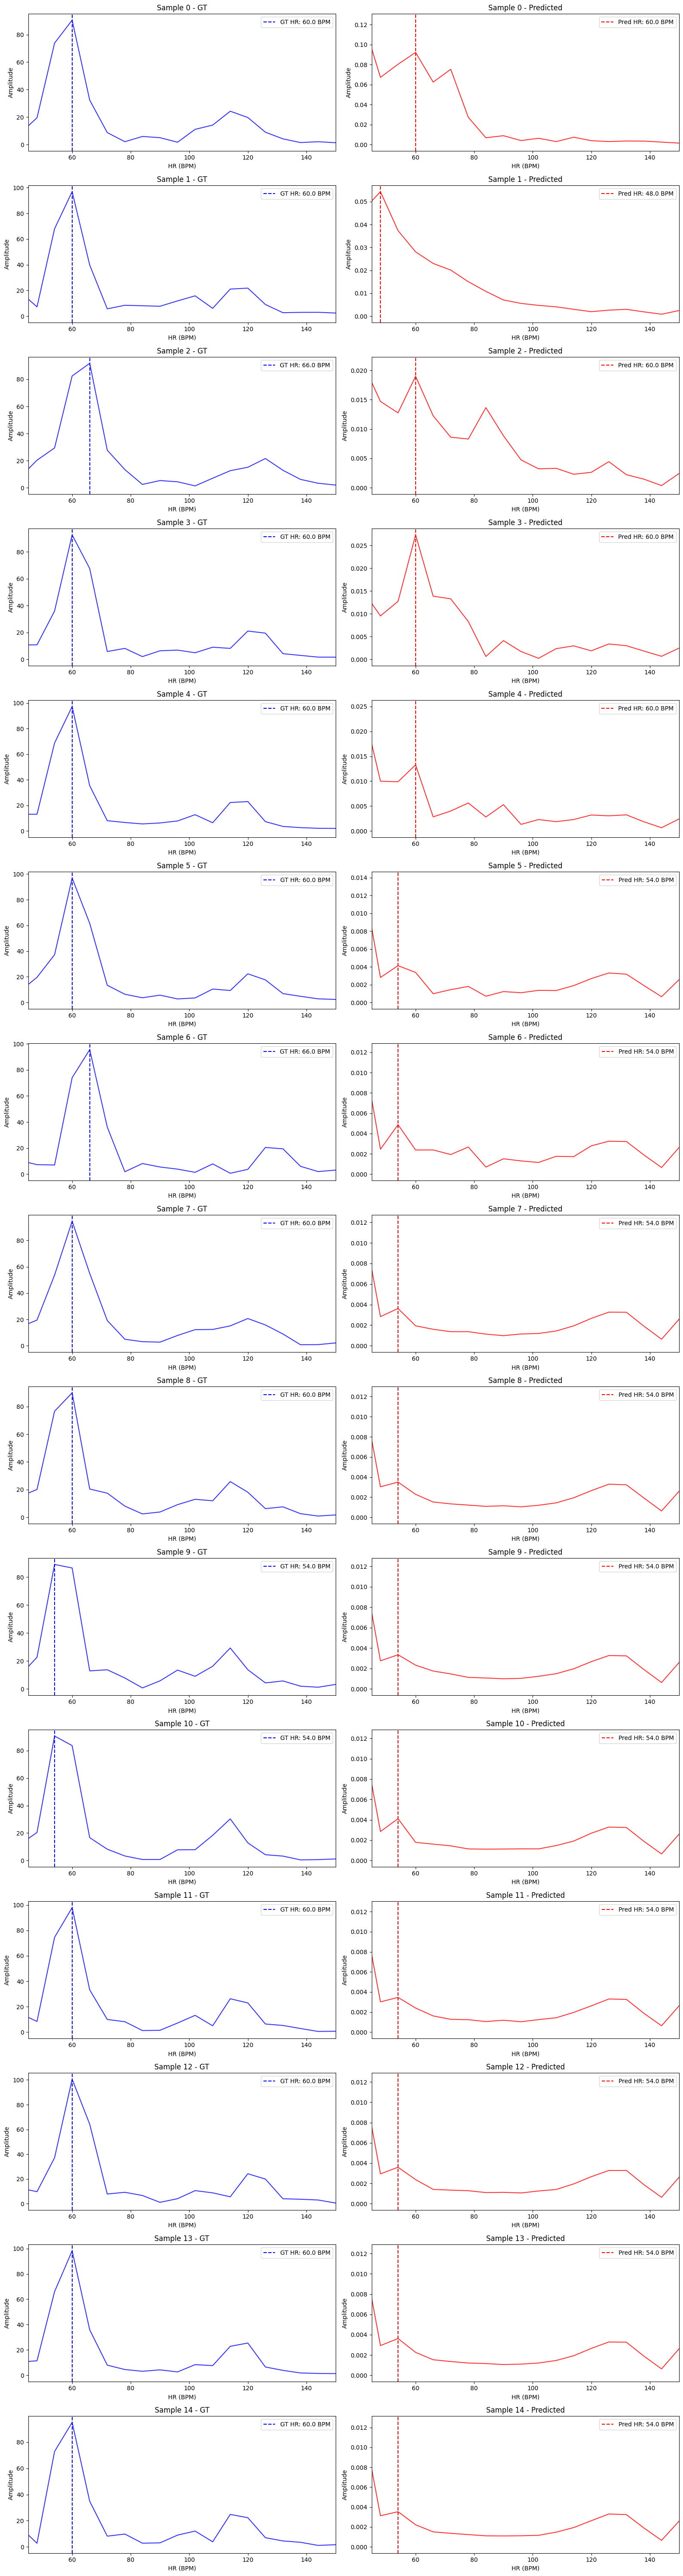

저장완료: fft_comparison.png


<Figure size 640x480 with 0 Axes>

In [5]:
from scipy.fft import fft

n_plot = 15
fig, axes = plt.subplots(n_plot, 2, figsize=(16, 4*n_plot))

for i in range(n_plot):
    pred_sig = all_preds_with_filter[i]
    gt_sig   = all_targets[i]

    hr_pred, psd_pred, x_hr_pred = hr_fft(pred_sig, fs=30)
    hr_gt,   psd_gt,   x_hr_gt   = hr_fft(gt_sig,   fs=30)

    # GT PSD
    axes[i, 0].plot(x_hr_gt, psd_gt, color='blue', alpha=0.8)
    axes[i, 0].axvline(hr_gt,   color='blue',  linestyle='--', label=f'GT HR: {hr_gt:.1f} BPM')
    axes[i, 0].set_xlim(0.75*60, 2.5*60)
    axes[i, 0].set_title(f'Sample {i} - GT')
    axes[i, 0].set_xlabel('HR (BPM)')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].legend()

    # Pred PSD
    axes[i, 1].plot(x_hr_pred, psd_pred, color='red', alpha=0.8)
    axes[i, 1].axvline(hr_pred, color='red',   linestyle='--', label=f'Pred HR: {hr_pred:.1f} BPM')
    axes[i, 1].set_xlim(0.75*60, 2.5*60)
    axes[i, 1].set_title(f'Sample {i} - Predicted')
    axes[i, 1].set_xlabel('HR (BPM)')
    axes[i, 1].set_ylabel('Amplitude')
    axes[i, 1].legend()

plt.tight_layout()

plt.show()
plt.savefig(os.path.join(pic_save_dir, 'nirp_uv_valid_frequencydomain'), dpi= 100)
print("저장완료: fft_comparison.png")